# Predicting tracks for an interval or sequence

This tutorial predicts tracks for a genomic interval with `predict_interval`
and for a custom DNA string with `predict_sequence`. We first predict across
*CD19* in blood B cells (`UBERON:0000178_CL:0000236`), where bulk and
single-cell RNA-seq and ATAC-seq tracks are directly observed; we then
predict DNase-seq and histone ChIP-seq from a padded DNA string.
This tutorial builds on
[Choosing a condition](https://www.alphagenomedocs.com/colabs/v2/choosing_a_condition.html)
and [Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html).

Key activities:

*   Choose a condition and output types, and define a `genome.Interval`
*   Make track predictions using `predict_interval` and `predict_sequence`
*   Visualize bulk and single-cell track predictions

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)).

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

We first load GENCODE gene and transcript annotations in GTF format (see
[GENCODE data format](https://www.gencodegenes.org/pages/data_format.html)):

In [4]:
# The GTF file contains information on the location of all transcripts.
# Note that we use genome assembly hg38 for human.
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)

# Get the MANE transcripts (one curated transcript per locus).
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
gtf_transcripts_mane = gene_annotation.filter_to_mane_select_transcript(
    gtf_transcripts
)

# Set up transcript extractors using the information in the GTF file.
transcript_extractor_mane = transcript_utils.TranscriptExtractor(
    gtf_transcripts_mane
)

## Predict interval (bulk)

`predict_interval` predicts tracks for a reference genome `genome.Interval`. It
takes a condition, the interval, and a list of requested output types as input.

### Set condition and output type

Use a reference condition CURIE from
[Choosing a condition](https://www.alphagenomedocs.com/colabs/v2/choosing_a_condition.html):

In [5]:
# Set biosample.
target_condition = 'UBERON:0000178_CL:0000236'  # Blood B cells.

# Set output types.
target_output = [
    dna_client.OutputType.RNA_SEQ,  # Gene expression.
    dna_client.OutputType.ATAC,
]  # Accessibility.

> **Tip:** For expression conditioning (`cell_conditioning=`) alongside `cell_condition_name=` with your own human scRNA-seq counts, request `dna_client.OutputType.SC_GENE_EXPRESSION_DENOISED` for denoised single-cell gene expression as target output; see [Conditioning on your own single-cell data](https://www.alphagenomedocs.com/colabs/v2/conditioning_on_single_cell_data.html).

### Define interval

Define a genomic interval by creating a `genome.Interval` object (see
[Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html)).
Here we fetch the gene interval for *CD19* and resize it to 1 Mb:

In [6]:
# Fetch the location of the gene from the GTF file.
gene_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='CD19')

# Expand (resize) the interval to a model compatible size.
interval = gene_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

```{important}
Use a 1 Mb interval (`dna_client.SEQUENCE_LENGTH_1MB`) for best accuracy. See [Selecting a genomic region](https://www.alphagenomedocs.com/colabs/v2/selecting_a_genomic_region.html) for all supported lengths.
```

### Predict interval

Make predictions using `predict_interval`:

In [7]:
output = dna_model.predict_interval(
    interval=interval,
    requested_outputs=target_output,
    condition=target_condition,
)

Most requested output types return a `TrackData` object of shape `(num_positions, num_tracks)` (`SC_GENE_EXPRESSION` returns a `GeneExpressionData` object of shape `(num_genes, num_tracks)`, `SPLICE_JUNCTIONS` returns a `JunctionData` object, and `CELL_EMBEDDINGS` returns a `numpy.ndarray`; see [Key objects](https://www.alphagenomedocs.com/colabs/v2/key_objects.html)).

In [8]:
# Shape of RNA output.
output.rna_seq.values.shape

(1048576, 12)

A condition returns multiple tracks per output type across channels and strands.
Inspect `metadata["imputation_mode"]` to see which tracks were directly
`observed` in training and which are imputed:

In [9]:
output.rna_seq.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,polyA plus RNA-seq,encode,False,paired,encode
1,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode
2,UBERON:0000178_CL:0000236_total RNA-seq-encode...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,total RNA-seq,NaN,NaN,paired,encode
3,UBERON:0000178_CL:0000236_total RNA-seq-encode...,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,total RNA-seq,encode,False,single,encode
4,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,-,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,polyA plus RNA-seq,encode,False,paired,encode
5,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode
6,UBERON:0000178_CL:0000236_total RNA-seq-encode...,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,total RNA-seq,NaN,NaN,paired,encode
7,UBERON:0000178_CL:0000236_total RNA-seq-encode...,-,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,total RNA-seq,encode,False,single,encode
8,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,paired,encode
9,UBERON:0000178_CL:0000236_polyA plus RNA-seq-e...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,polyA plus RNA-seq,NaN,NaN,single,encode


### Subset tracks

Prediction containers can be filtered using convenience methods (such as
`.filter_to_protein_coding()`, `.filter_to_observed()`, and
`.filter_to_positive_strand()`) or by indexing with boolean masks over
`.metadata` and `.gene_metadata`:

The metadata shows the `imputation_mode`, assay protocol (`polyA plus RNA-seq`
and `total RNA-seq`), and DNA strand of each track:

In [10]:
# Subset RNA-seq to paired, observed positive-strand tracks.
mask_rna = (
    (output.rna_seq.metadata.endedness == 'paired')
    & (output.rna_seq.metadata['imputation_mode'] == 'observed')
    & (output.rna_seq.metadata.strand == '+')
).values
rna_subset = output.rna_seq[:, mask_rna]

# Subset ATAC to observed tracks.
mask_atac = ((output.atac.metadata['imputation_mode'] == 'observed')).values
atac_subset = output.atac[:, mask_atac]

### Visualize

Plot the predicted RNA-seq and ATAC-seq tracks alongside the MANE Select
transcripts in the 1 Mb region, zooming in around *CD19*. See
[Plotting predictions](https://www.alphagenomedocs.com/colabs/v2/plotting_predictions.html)
for details.

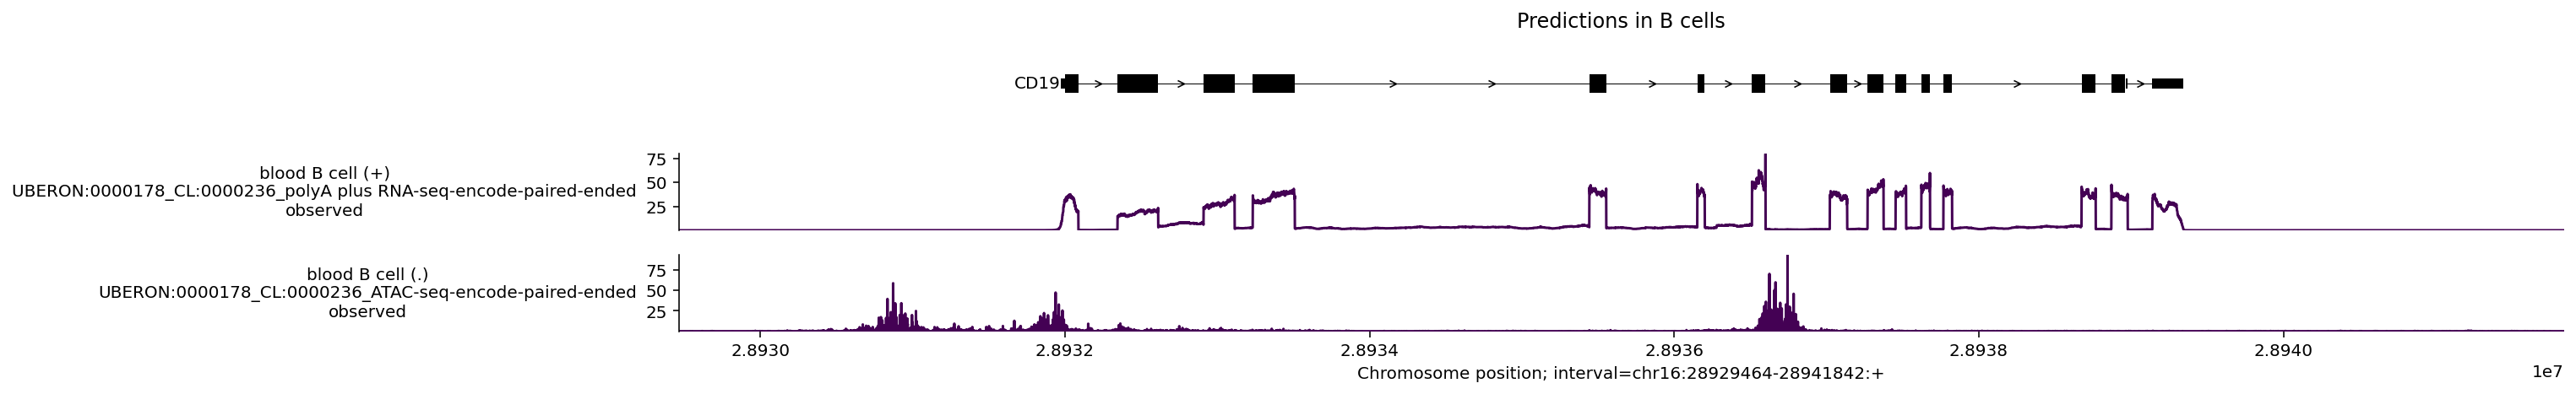

In [11]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    components=[
        # Add transcripts to plot.
        plot_components.TranscriptAnnotation(transcripts),
        # Add RNA output.
        plot_components.Tracks(
            rna_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add ATAC output.
        plot_components.Tracks(
            atac_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 5000),
    title='Predictions in B cells',
)

plt.show()

## Predict interval (pseudobulk)

For pseudobulk scRNA-seq (`SC_GENE_EXPRESSION`), the model returns one
predicted expression value (in counts per million) per annotated gene in the
interval rather than a base-pair coverage track.

### Predict interval

Make single-cell predictions using `predict_interval`:

In [12]:
output_sc = dna_model.predict_interval(
    interval=interval,  # Same interval.
    requested_outputs=[
        dna_client.OutputType.SC_GENE_EXPRESSION,  # SC RNA.
        dna_client.OutputType.SC_ATAC,
    ],  # SC ATAC.
    condition=target_condition,  # Same condition.
)

The scATAC-seq output returns a `TrackData` object whose track metadata can be
accessed as follows:

In [13]:
# View track metadata for sc ATAC.
output_sc.sc_atac.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline
0,UBERON:0000178_CL:0000236_EasySci-ATAC-easy_sc...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci-ATAC,nuclear,easy_sci
1,UBERON:0000178_CL:0000236_SHARE-seq-cellranger...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,cellranger
2,UBERON:0000178_CL:0000236_scATAC-seq 10X-bowti...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scATAC-seq 10X,nuclear,encode
3,UBERON:0000178_CL:0000236_scATAC-seq 10X-cellr...,.,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,scATAC-seq 10X,nuclear,cellranger
4,UBERON:0000178_CL:0000236_sciATAC-seq-bowtie2-...,.,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,sciATAC-seq,nuclear,encode


The scRNA-seq output predicts gene expression per gene in a
`GeneExpressionData` object with both `.track_metadata` and `.gene_metadata`:

In [14]:
# View track metadata for sc gene expression.
output_sc.sc_gene_expression.track_metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,suspension_type,data_pipeline,cellxgene_dataset_id,paper_doi
0,UBERON:0000178_CL:0000236_EasySci-easy_sci-nuc...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci,nuclear,easy_sci,NaN,NaN
1,UBERON:0000178_CL:0000236_SHARE-seq-share_seq-...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,share_seq,NaN,NaN
2,UBERON:0000178_CL:0000236_SPLIT-seq-star_solo-...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SPLIT-seq,nuclear,encode,NaN,NaN
3,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-cell...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,cell,cellranger,NaN,NaN
4,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-cell...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,nuclear,cellranger,NaN,NaN
5,UBERON:0000178_CL:0000236_scRNA-seq 10X 3-star...,+,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,scRNA-seq 10X 3,nuclear,encode,NaN,NaN
6,UBERON:0000178_CL:0000236_scRNA-seq 10X 5-cell...,+,UBERON:0000178_CL:0000236,observed,primary_cell,blood B cell,scRNA-seq 10X 5,cell,cellranger,3a8a77a6-f069-479c-a2c1-252feafd0106,10.1016/j.cell.2025.02.017
7,UBERON:0000178_CL:0000236_EasySci-easy_sci-nuc...,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,EasySci,nuclear,easy_sci,NaN,NaN
8,UBERON:0000178_CL:0000236_SHARE-seq-share_seq-...,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SHARE-seq,nuclear,share_seq,NaN,NaN
9,UBERON:0000178_CL:0000236_SPLIT-seq-star_solo-...,-,UBERON:0000178_CL:0000236,imputed_supported,primary_cell,blood B cell,SPLIT-seq,nuclear,encode,NaN,NaN


In [15]:
# View gene metadata for sc gene expression.
output_sc.sc_gene_expression.gene_metadata

,gene_id,Chromosome,Start,End,strand,gene_name,gene_type
0,ENSG00000103472.10,chr16,29074975,29116718,+,RRN3P2,lncRNA
1,ENSG00000168488.19,chr16,28822998,28837237,+,ATXN2L,protein_coding
2,ENSG00000169682.18,chr16,28974220,28984548,+,SPNS1,protein_coding
3,ENSG00000176046.9,chr16,28532707,28539008,-,NUPR1,protein_coding
4,ENSG00000176476.9,chr16,28553914,28591790,+,SGF29,protein_coding
...,...,...,...,...,...,...,...
76,ENSG00000289756.1,chr16,28620062,28623482,-,ENSG00000289756,transcribed_unprocessed_pseudogene
77,ENSG00000290677.1,chr16,29103656,29108108,-,ENSG00000290677,lncRNA
78,ENSG00000290680.1,chr16,29350745,29370272,+,ENSG00000290680,lncRNA
79,ENSG00000291188.1,chr16,29114716,29217860,+,ENSG00000291188,lncRNA


### Subset tracks

Prediction containers can be filtered using convenience methods (such as
`.filter_to_protein_coding()`, `.filter_to_observed()`, and
`.filter_to_positive_strand()`) or by indexing with boolean masks over
`.metadata` and `.gene_metadata`:

In [16]:
# Subset single-cell gene expression to positive-strand protein-coding genes and observed + tracks.
rna_subset = (
    output_sc.sc_gene_expression.filter_to_protein_coding()
    .filter_to_observed()
    .filter_to_positive_strand()
)
rna_subset = rna_subset[rna_subset.gene_metadata['strand'] == '+']

# Subset scATAC to observed tracks.
mask_atac = (
    (output_sc.sc_atac.metadata['imputation_mode'] == 'observed')
).values
atac_subset = output_sc.sc_atac[:, mask_atac]

### Visualize

We filter to protein-coding genes and observed positive-strand (`+`) tracks,
since *CD19* is transcribed from the positive strand, and plot single-interval
`SC_GENE_EXPRESSION` outputs with `plot_components.GeneExpression` (use
`plot_components.OverlaidGeneExpression` for variant REF/ALT comparisons):

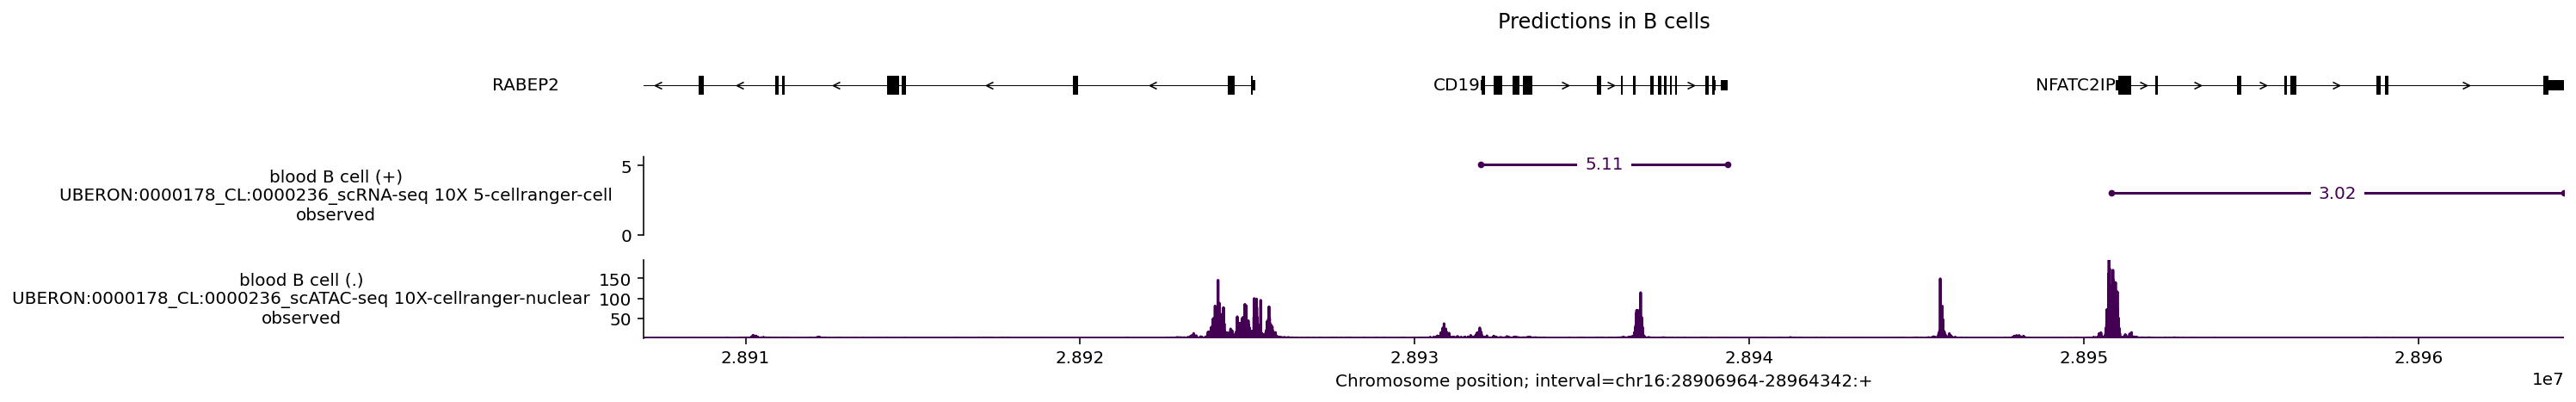

In [17]:
# Extract transcripts.
transcripts = transcript_extractor_mane.extract(interval)

# Plot.
plot_components.plot(
    components=[
        # Add transcripts to plot.
        plot_components.TranscriptAnnotation(transcripts),
        # Add single cell RNA output.
        plot_components.GeneExpression(
            rna_subset,
            log_scale=True,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
        # Add single cell ATAC output.
        plot_components.Tracks(
            atac_subset,
            ylabel_template=(
                '{biosample_name} ({strand})\n{name}\n{imputation_mode}'
            ),
        ),
    ],
    interval=gene_interval.resize(gene_interval.width + 50000),
    title='Predictions in B cells',
)

plt.show()

See [Plotting predictions](https://www.alphagenomedocs.com/colabs/v2/plotting_predictions.html) and the [visualization API reference](https://www.alphagenomedocs.com/api/visualization.html) for additional plot components and styling options.

## Predict a sequence

Instead of an interval on the reference genome, you can predict for any DNA
sequence of a supported length with `predict_sequence`. Pad shorter sequences
with `N` to reach one of the supported sequence lengths. Sequence predictions are useful for synthetic or edited sequences,
though gene-level `SC_GENE_EXPRESSION` requires reference genome coordinates
(`predict_interval`, `predict_variant`, or `score_variant`).

Here we predict DNase-seq tracks in lung tissue (`UBERON:0002048`) for a DNA
sequence padded to 16 kb (`dna_client.SEQUENCE_LENGTH_16KB`, 16,384 bp; for
endogenous genomic loci, prefer 1 Mb via `dna_client.SEQUENCE_LENGTH_1MB`):

In [18]:
output = dna_model.predict_sequence(
    sequence='GATTACA'.center(
        dna_client.SEQUENCE_LENGTH_16KB, 'N'
    ),  # Pad to valid sequence length.
    requested_outputs=[dna_client.OutputType.DNASE],
    condition='UBERON:0002048',  # Lung.
)

`output.dnase` is a `TrackData` object with `.values` of shape
`(sequence_length, num_tracks)` and track descriptions in `.metadata` (see
[Key objects](https://www.alphagenomedocs.com/colabs/v2/key_objects.html)):

In [19]:
dnase = output.dnase
type(dnase)

alphagenome.data.track_data.TrackData

Let's look at the track metadata:

In [20]:
dnase.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0002048_DNase-seq-encode-paired-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,paired,encode
1,UBERON:0002048_DNase-seq-encode-single-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,single,encode


Here lung DNase-seq has 2 channels (paired-end and single-end), so `.metadata`
has 2 rows. Track metadata is especially useful for stranded assays (such as
CAGE and RNA-seq) and for checking whether each track is observed or imputed.

We can index tracks with a boolean mask on `metadata['imputation_mode']` to keep
only directly measured (`observed`) tracks:

In [21]:
observed_mask = (dnase.metadata.imputation_mode == 'observed').values
subset_dnase = dnase[:, observed_mask]
subset_dnase.metadata

,name,strand,biosample_curie,imputation_mode,biosample_type,biosample_name,Assay title,data_source,genetically_modified,endedness,data_pipeline
0,UBERON:0002048_DNase-seq-encode-paired-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,paired,encode
1,UBERON:0002048_DNase-seq-encode-single-ended,.,UBERON:0002048,observed,tissue,lung,DNase-seq,encode,False,single,encode


Histone ChIP-seq (`CHIP_HISTONE`) and TF ChIP-seq (`CHIP_TF`) are predicted at
128 bp resolution rather than 1 bp:

In [22]:
output = dna_model.predict_sequence(
    sequence='GATTACA'.center(
        dna_client.SEQUENCE_LENGTH_16KB, 'N'
    ),  # Pad to valid sequence length.
    requested_outputs=[
        dna_client.OutputType.CHIP_HISTONE,
    ],
    condition='UBERON:0000955',  # Brain.
)

print(f'ChIP predictions shape: {output.chip_histone.values.shape}')
print(
    'ChIP predictions resolution:'
    f' {int(dna_client.SEQUENCE_LENGTH_16KB / output.chip_histone.values.shape[0])} bp'
)

ChIP predictions shape: (128, 43)
ChIP predictions resolution: 128 bp


Next in the core workflow, we will [predict the effect of a variant](https://www.alphagenomedocs.com/colabs/v2/predict_variant.html).